In [1]:
import numpy as np
from collections import Counter
from tqdm import tqdm

In [2]:
def euclidean_distance(x1, x2):
  distance = np.sqrt(np.sum((x1-x2)**2))
  #distance = 0
  #for i in range(len(x1)):
  #  distance += (x1[i] - x2[i])**2

  return distance

In [3]:
class KNN:
  def __init__(self, k=3):
    self.k = k

  def fit(self, X, y):
    self.X_train = X
    self.Y_train = y

  def predict(self, X):
    # tqdm(X, total=len(X), leave=False)
    predictions = [self._predict(x) for x in X]
    return predictions

  def _predict(self, X):
    # compute the distance
    distances = [euclidean_distance(X, x_train) for x_train in self.X_train]

    # get the closed k
    k_indices = np.argsort(distances)[:self.k]
    k_nearest_labels = [self.Y_train[i] for i in k_indices]

    # majority vote
    most_common = Counter (k_nearest_labels).most_common()[0][0]
    return most_common

In [4]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
cmap = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

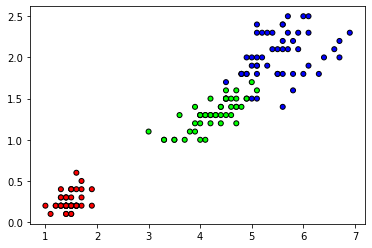


 0.9666666666666667
[1, 2, 2, 0, 1, 0, 0, 0, 1, 2, 1, 0, 2, 1, 0, 1, 2, 0, 2, 1, 1, 1, 1, 1, 2, 0, 2, 1, 2, 0]


In [5]:
iris = datasets.load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

plt.figure()
plt.scatter(X[:,2],X[:,3], c=y, cmap = cmap, edgecolor='k', s=25)
plt.show()

clf = KNN(k=5)
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)

acc = np.sum(predictions == y_test) / len(y_test)
print('\n', acc)

print(predictions)

In [6]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Function to plot images
def plot_image(image, title="Image"):
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    # plt.axis("off")
    plt.show()


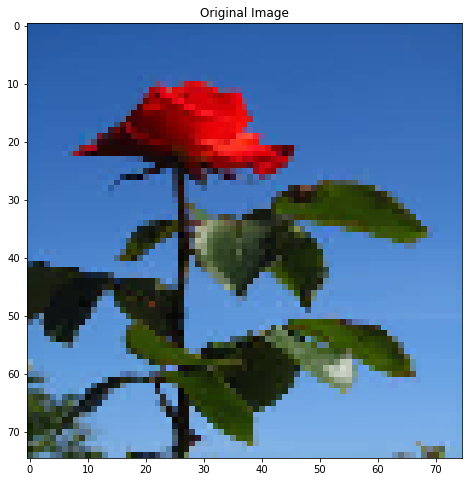

In [12]:
import cv2
# Load image for segmentation
image_path = 'testimage2.jpg'  # Replace with your image file
#image_path = 'simfl.png'  # Replace with your image file
image = cv2.resize(cv2.imread(image_path),(75,75))

if image is None:
    print("Error: Image not found!")
else:
    plot_image(image, "Original Image")


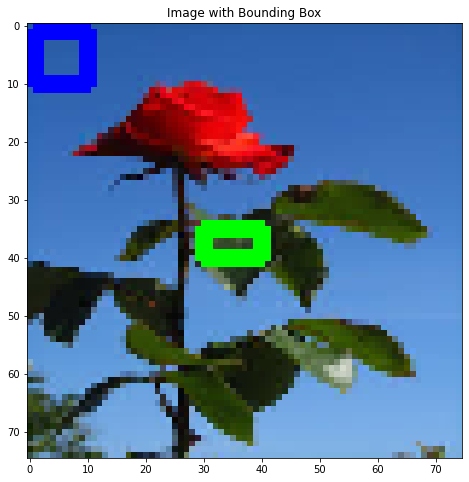

In [13]:

# Define the bounding box coordinates (top-left and bottom-right corners)
# Example: bounding box covering the region of interest (foreground)
bx1, by1, bx2, by2 = 1, 1, 10, 10  # Modify these coordinates for your case
fx1, fy1, fx2, fy2 = 30, 35, 40, 40  # Modify these coordinates for your case

# Display the bounding box on the image
image_with_bbox = image.copy()
cv2.rectangle(image_with_bbox, (bx1, by1), (bx2, by2), (255, 0, 0), 2)
cv2.rectangle(image_with_bbox, (fx1, fy1), (fx2, fy2), (0, 255, 0), 2)

plot_image(image_with_bbox, "Image with Bounding Box")

# Prepare data for segmentation: features are (RGB + pixel location)
h, w, _ = image.shape
X = np.zeros((h * w, 5))  # 5 features: R, G, B, x, y
y = np.zeros((h * w,))    # Labels: 1 for foreground, 0 for background

# Fill the feature matrix
for i in range(h):
    for j in range(w):
        X[i * w + j, :3] = image[i, j]  # RGB values
        X[i * w + j, 3:] = [i, j]       # Pixel coordinates

# Define foreground and background based on bounding box
for i in range(h):
    for j in range(w):
        if fx1 <= j <= fx2 and fy1 <= i <= fy2:
            y[i * w + j] = 1  # Foreground
        elif bx1 <= j <= bx2 and by1 <= i <= by2:
            y[i * w + j] = 2  # Background

image = np.uint8(image)

In [14]:

# Train a KNN model using the labeled pixels
knn = KNN(k=5)
X_train = X[y!=0,0:3]
y_train = y[y!=0]

print(np.shape(X_train))
print(np.shape(X_train))
knn.fit(X_train, y_train)

# Predict the class of each pixel (foreground/background)
y_pred = knn.predict(X[:,0:3])
print(np.shape(y_pred))

(166, 3)
(166, 3)
(5625,)


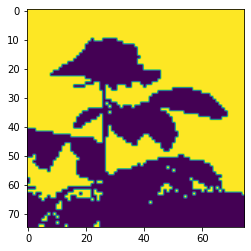

In [15]:
# Reshape the result back to the original image size
segmentation = np.reshape(y_pred, (h, w))

# Visualize the segmentation result
plt.imshow(segmentation)

